# Tugas Take-Home Sesi 05 — Transfer Learning untuk Klasifikasi Image dengan Data Terbatas

**Nama:** WINKO  
**NIM:** 2802388535

Eksperimen B1–B5 di notebook ini dijalankan pada subset 10 kelas Oxford-IIIT Pet. Setup yang dipakai sama di semua kondisi: ResNet-18, input 224×224, batch 32, AdamW, CrossEntropyLoss, early stopping patience 5, dan seed 42.

## 1. Setup & Reproducibility

Semua seed dikunci (Python, NumPy, PyTorch, CUDA) supaya hasil run bisa diulang.

In [1]:
import os, time, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", DEVICE)
print("PyTorch:", torch.__version__)

Device : cuda
PyTorch: 2.11.0+cu130


## 2. Dataset: Oxford-IIIT Pet (Subset 10 Kelas)

Alurnya: download dataset → lihat daftar kelasnya → ambil 10 kelas (5 ras kucing + 5 ras anjing) → split stratified 70% train / 15% val / 15% test.

In [2]:
# Langkah 1: unduh dataset (split trainval, ~200 image per kelas)
raw_trainval = datasets.OxfordIIITPet(
    root="./data", split="trainval",
    target_types="category", download=True, transform=None
)

# Lihat dulu semua kelas yang ada di dataset
ALL_CLASSES = raw_trainval.classes
print(len(ALL_CLASSES), "kelas tersedia:")
for i, c in enumerate(ALL_CLASSES):
    print(f"{i:2d}. {c}")

100%|██████████| 792M/792M [00:20<00:00, 38.3MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 16.2MB/s]


37 kelas tersedia:
 0. Abyssinian
 1. American Bulldog
 2. American Pit Bull Terrier
 3. Basset Hound
 4. Beagle
 5. Bengal
 6. Birman
 7. Bombay
 8. Boxer
 9. British Shorthair
10. Chihuahua
11. Egyptian Mau
12. English Cocker Spaniel
13. English Setter
14. German Shorthaired
15. Great Pyrenees
16. Havanese
17. Japanese Chin
18. Keeshond
19. Leonberger
20. Maine Coon
21. Miniature Pinscher
22. Newfoundland
23. Persian
24. Pomeranian
25. Pug
26. Ragdoll
27. Russian Blue
28. Saint Bernard
29. Samoyed
30. Scottish Terrier
31. Shiba Inu
32. Siamese
33. Sphynx
34. Staffordshire Bull Terrier
35. Wheaten Terrier
36. Yorkshire Terrier


In [3]:
# Langkah 2: pilih 10 kelas dari daftar di atas (5 kucing + 5 anjing)
# Pasangan yang mirip (British_Shorthair vs Russian_Blue, chihuahua vs
# miniature_pinscher) sengaja dipilih untuk bahan failure analysis
CAT_CLASSES = ["Abyssinian", "British_Shorthair", "Russian_Blue", "Siamese", "Sphynx"]
DOG_CLASSES = ["beagle", "boxer", "chihuahua", "miniature_pinscher", "pug"]
SELECTED = CAT_CLASSES + DOG_CLASSES

# Pemetaan nama -> id kelas dataset (toleran huruf besar/kecil)
norm = {c.lower().replace(" ", "_"): c for c in ALL_CLASSES}
selected_ids = [ALL_CLASSES.index(norm[c.lower().replace(" ", "_")]) for c in SELECTED]
label_map = {orig: i for i, orig in enumerate(selected_ids)}
CLASS_NAMES = [ALL_CLASSES[i].replace("_", " ") for i in selected_ids]
print("Class chosen:", CLASS_NAMES)

# Kumpulkan indeks images yang termasuk kelas terpilih
labels_all = raw_trainval._labels
indices = [i for i, lbl in enumerate(labels_all) if lbl in selected_ids]
labels = [labels_all[i] for i in indices]
print("Total images subset:", len(indices))

Class chosen: ['Abyssinian', 'British Shorthair', 'Russian Blue', 'Siamese', 'Sphynx', 'Beagle', 'Boxer', 'Chihuahua', 'Miniature Pinscher', 'Pug']
Total images subset: 999


In [4]:
# Langkah 3: stratified split 70/15/15
idx_train, idx_temp, y_train, y_temp = train_test_split(
    indices, labels, test_size=0.30, stratify=labels, random_state=SEED
)
idx_val, idx_test, y_val, y_test = train_test_split(
    idx_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

print(f"train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}")

# Verifikasi distribusi kelas per split (stratified)
for name, ys in [("train", y_train), ("val", y_val), ("test", y_test)]:
    vc = pd.Series(ys).value_counts().sort_index()
    print(f"{name:5s} -> min={vc.min()}, max={vc.max()} per kelas")

train=699  val=150  test=150
train -> min=69, max=70 per kelas
val   -> min=15, max=15 per kelas
test  -> min=15, max=15 per kelas


## 3. Transformasi & DataLoader

Ada tiga pipeline:
- `train_tf_plain`: Resize + CenterCrop + Normalize doang — dipakai B1–B3 dan skenario tanpa aug di B4.
- `train_tf_aug`: ditambah augmentasi (RandomResizedCrop, HFlip, Rotation 15°, ColorJitter) — dipakai B4-aug dan B5.
- `eval_tf`: `weights.transforms()`, deterministik buat val/test.

In [5]:
weights_r18 = models.ResNet18_Weights.IMAGENET1K_V1
eval_tf = weights_r18.transforms()

IMGNET_MEAN = [0.485, 0.456, 0.406]
IMGNET_STD  = [0.229, 0.224, 0.225]

train_tf_plain = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMGNET_MEAN, std=IMGNET_STD),
])

train_tf_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMGNET_MEAN, std=IMGNET_STD),
])

class PetSubset(Dataset):
    """Subset dataset dengan transform dan remapping label 0-9."""
    def __init__(self, base, indices, transform, label_map):
        self.base, self.indices = base, indices
        self.transform, self.label_map = transform, label_map
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, lbl = self.base[self.indices[i]]
        if img.mode != "RGB":  # beberapa image dataset bukan RGB
            img = img.convert("RGB")
        return self.transform(img), self.label_map[lbl]

BATCH = 32
g = torch.Generator()
g.manual_seed(SEED)

def make_loaders(train_tf):
    ds_tr = PetSubset(raw_trainval, idx_train, train_tf, label_map)
    ds_va = PetSubset(raw_trainval, idx_val,   eval_tf,  label_map)
    ds_te = PetSubset(raw_trainval, idx_test,  eval_tf,  label_map)
    return (
        DataLoader(ds_tr, batch_size=BATCH, shuffle=True,  num_workers=2, generator=g),
        DataLoader(ds_va, batch_size=BATCH, shuffle=False, num_workers=2),
        DataLoader(ds_te, batch_size=BATCH, shuffle=False, num_workers=2),
    )

# Sanity check bentuk batch
tr, va, te = make_loaders(train_tf_plain)
xb, yb = next(iter(tr))
print("batch train:", xb.shape, "label:", yb.shape, "| val batches:", len(va), "| test batches:", len(te))

batch train: torch.Size([32, 3, 224, 224]) label: torch.Size([32]) | val batches: 5 | test batches: 5


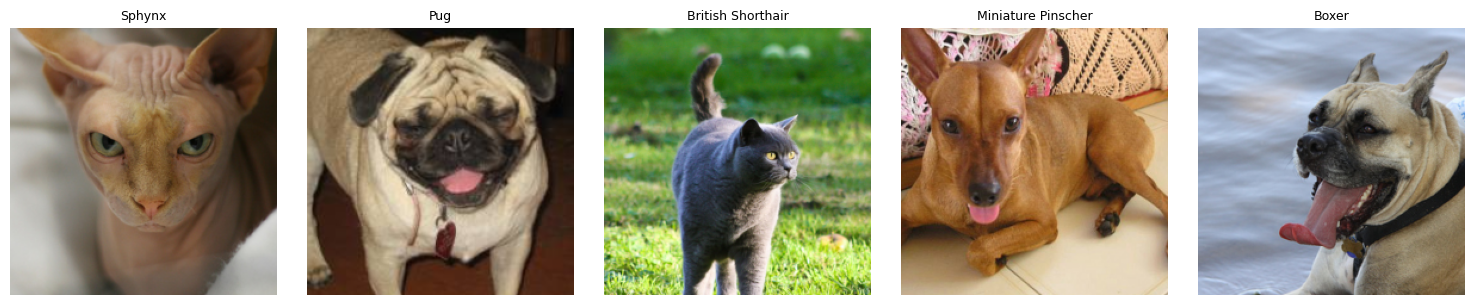

In [6]:
# Visualisasi sampel training (tanpa augmentasi)
mean_t = torch.tensor(IMGNET_MEAN).view(3, 1, 1)
std_t  = torch.tensor(IMGNET_STD).view(3, 1, 1)

def show_images(tensors, titles, ncols=5):
    n = len(tensors)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    if n == 1:
        axes = [axes]
    for ax, t, ttl in zip(axes, tensors, titles):
        img = (t.cpu() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0)
        ax.imshow(img)
        ax.set_title(ttl, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_images(
    [xb[i] for i in range(5)],
    [CLASS_NAMES[yb[i].item()] for i in range(5)]
)

## 4. Training Engine

Satu loop training buat semua kondisi: catat metrik tiap epoch, early stopping monitor val_loss (patience 5), dan bobot terbaik disimpan buat evaluasi test.

In [7]:
def eval_model(model, loader, criterion=None):
    model.eval()
    tot_loss, n, preds, gts = 0.0, 0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            if criterion is not None:
                tot_loss += criterion(out, y).item() * len(y)
            preds += out.argmax(1).cpu().tolist()
            gts   += y.cpu().tolist()
            n     += len(y)
    acc = accuracy_score(gts, preds)
    f1  = f1_score(gts, preds, average="macro", zero_division=0)
    return (tot_loss / n if criterion else None), acc, f1


def train_model(name, model, loaders, optimizer, criterion, max_epochs=50, patience=5):
    train_loader, val_loader, _ = loaders
    model = model.to(DEVICE)
    history = []
    best = {"val_loss": float("inf"), "state": None, "epoch": 0}
    epochs_no_improve = 0
    t0 = time.time()

    for epoch in range(1, max_epochs + 1):
        model.train()
        tr_loss, tr_correct, tr_n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            tr_loss    += loss.item() * len(y)
            tr_correct += (out.argmax(1) == y).sum().item()
            tr_n       += len(y)

        va_loss, va_acc, va_f1 = eval_model(model, val_loader, criterion)
        history.append({
            "epoch": epoch,
            "train_loss": tr_loss / tr_n,
            "train_acc": tr_correct / tr_n,
            "val_loss": va_loss,
            "val_acc": va_acc,
            "val_f1_macro": va_f1,
        })
        h = history[-1]
        print(f"[{name}] ep{epoch:02d} | "
              f"loss {h['train_loss']:.4f} acc {h['train_acc']:.3f} | "
              f"val_loss {h['val_loss']:.4f} val_acc {h['val_acc']:.3f} f1 {h['val_f1_macro']:.3f}")

        if va_loss < best["val_loss"]:
            best.update(
                val_loss=va_loss, epoch=epoch,
                state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            )
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping pada epoch {epoch}")
                break

    elapsed = time.time() - t0
    print(f"Selesai: {len(history)} epoch, {elapsed:.1f} detik, best val_loss={best['val_loss']:.4f} (ep{best['epoch']})")
    return history, best, elapsed

In [8]:
RESULTS = {}
MODELS  = {}
os.makedirs("logs", exist_ok=True)

def run_experiment(code, desc, model, optimizer, train_tf, lr_note, max_epochs=50, patience=5):
    """Jalankan satu kondisi eksperimen: training + evaluasi test + simpan raw log."""
    print(f"\n{'=' * 60}\n{code}: {desc}\n{'=' * 60}")
    loaders = make_loaders(train_tf)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"Trainable params: {trainable:,} / {total:,}")

    history, best, elapsed = train_model(
        code, model, loaders, optimizer, nn.CrossEntropyLoss(), max_epochs, patience
    )

    # Evaluasi test set dengan bobot terbaik
    model.load_state_dict(best["state"])
    model = model.to(DEVICE)
    _, test_acc, test_f1 = eval_model(model, loaders[2], nn.CrossEntropyLoss())

    # Simpan log mentah (CSV per epoch + bobot terbaik)
    pd.DataFrame(history).to_csv(f"logs/log_{code}.csv", index=False)
    torch.save(best["state"], f"logs/{code}_best.pt")

    summary = {
        "condition": code,
        "description": desc,
        "trainable_params": trainable,
        "total_params": total,
        "lr": lr_note,
        "epochs_run": len(history),
        "best_epoch": best["epoch"],
        "training_time_sec": round(elapsed, 1),
        "best_val_loss": round(best["val_loss"], 4),
        "best_val_acc": round(history[best["epoch"] - 1]["val_acc"], 4),
        "test_acc": round(test_acc, 4),
        "test_f1_macro": round(test_f1, 4),
    }
    RESULTS[code] = summary
    MODELS[code] = model
    print(json.dumps(summary, indent=2))
    return model, history, summary

## 5. Kondisi Eksperimen

### B1 — Baseline from Scratch

ResNet-18 `weights=None`, dilatih dari nol di 10 kelas. Ini patokan bawahnya — buat lihat seberapa besar efek bobot pretrained. Train tanpa augmentasi.

In [9]:
set_seed()
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
opt_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)

model_b1, hist_b1, sum_b1 = run_experiment(
    "B1_scratch",
    "ResNet-18 dari nol (weights=None), tanpa augmentasi",
    model_b1, opt_b1, train_tf_plain,
    {"all_params": 1e-3}
)


B1_scratch: ResNet-18 dari nol (weights=None), tanpa augmentasi
Trainable params: 11,181,642 / 11,181,642
[B1_scratch] ep01 | loss 2.4978 acc 0.136 | val_loss 3.7987 val_acc 0.187 f1 0.123
[B1_scratch] ep02 | loss 2.1846 acc 0.217 | val_loss 2.6408 val_acc 0.200 f1 0.103
[B1_scratch] ep03 | loss 2.0335 acc 0.252 | val_loss 2.1232 val_acc 0.227 f1 0.180
[B1_scratch] ep04 | loss 1.9013 acc 0.308 | val_loss 1.9598 val_acc 0.253 f1 0.224
[B1_scratch] ep05 | loss 1.7681 acc 0.349 | val_loss 2.4734 val_acc 0.240 f1 0.218
[B1_scratch] ep06 | loss 1.7866 acc 0.366 | val_loss 2.3835 val_acc 0.253 f1 0.189
[B1_scratch] ep07 | loss 1.6432 acc 0.395 | val_loss 2.7678 val_acc 0.207 f1 0.146
[B1_scratch] ep08 | loss 1.4641 acc 0.488 | val_loss 2.1376 val_acc 0.260 f1 0.225
[B1_scratch] ep09 | loss 1.3690 acc 0.531 | val_loss 2.1795 val_acc 0.287 f1 0.272
Early stopping pada epoch 9
Selesai: 9 epoch, 56.1 detik, best val_loss=1.9598 (ep4)
{
  "condition": "B1_scratch",
  "description": "ResNet-18 da

### B2 — Feature Extraction

ResNet-18 pretrained, seluruh backbone difreeze (`requires_grad=False`), terus `fc` diganti `nn.Linear(512, 10)`. Yang dilatih cuma head-nya (~5.130 params). Tanpa augmentasi.

In [10]:
set_seed()
model_b2 = models.resnet18(weights=weights_r18)
for p in model_b2.parameters():
    p.requires_grad = False
model_b2.fc = nn.Linear(model_b2.fc.in_features, 10)

opt_b2 = torch.optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)

model_b2, hist_b2, sum_b2 = run_experiment(
    "B2_feature_extraction",
    "Freeze backbone, latih classifier head saja, tanpa augmentasi",
    model_b2, opt_b2, train_tf_plain,
    {"fc": 1e-3}
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]



B2_feature_extraction: Freeze backbone, latih classifier head saja, tanpa augmentasi
Trainable params: 5,130 / 11,181,642
[B2_feature_extraction] ep01 | loss 1.7241 acc 0.482 | val_loss 1.1597 val_acc 0.793 f1 0.786
[B2_feature_extraction] ep02 | loss 0.9141 acc 0.844 | val_loss 0.7404 val_acc 0.860 f1 0.861
[B2_feature_extraction] ep03 | loss 0.5932 acc 0.903 | val_loss 0.5593 val_acc 0.907 f1 0.906
[B2_feature_extraction] ep04 | loss 0.4307 acc 0.947 | val_loss 0.4430 val_acc 0.920 f1 0.918
[B2_feature_extraction] ep05 | loss 0.3591 acc 0.936 | val_loss 0.3919 val_acc 0.913 f1 0.912
[B2_feature_extraction] ep06 | loss 0.3113 acc 0.954 | val_loss 0.3638 val_acc 0.913 f1 0.912
[B2_feature_extraction] ep07 | loss 0.2775 acc 0.956 | val_loss 0.3207 val_acc 0.940 f1 0.940
[B2_feature_extraction] ep08 | loss 0.2336 acc 0.967 | val_loss 0.3253 val_acc 0.920 f1 0.918
[B2_feature_extraction] ep09 | loss 0.2120 acc 0.967 | val_loss 0.2782 val_acc 0.927 f1 0.926
[B2_feature_extraction] ep10 | 

### B3 — Progressive Fine-Tuning

Masih dari pretrained, tapi `layer4` dan `fc` dibuka. Pakai differential LR biar bobot bawaan nggak langsung rusak: layer4 = 1e-4, fc = 1e-3. Tanpa augmentasi.

In [11]:
set_seed()
model_b3 = models.resnet18(weights=weights_r18)
for p in model_b3.parameters():
    p.requires_grad = False
for p in model_b3.layer4.parameters():
    p.requires_grad = True
model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)

opt_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(),     "lr": 1e-3},
], weight_decay=1e-2)

model_b3, hist_b3, sum_b3 = run_experiment(
    "B3_finetune",
    "Unfreeze layer4 + fc, differential LR, tanpa augmentasi",
    model_b3, opt_b3, train_tf_plain,
    {"layer4": 1e-4, "fc": 1e-3}
)


B3_finetune: Unfreeze layer4 + fc, differential LR, tanpa augmentasi
Trainable params: 8,398,858 / 11,181,642
[B3_finetune] ep01 | loss 1.0340 acc 0.711 | val_loss 0.2718 val_acc 0.933 f1 0.933
[B3_finetune] ep02 | loss 0.1404 acc 0.989 | val_loss 0.1821 val_acc 0.940 f1 0.940
[B3_finetune] ep03 | loss 0.0473 acc 1.000 | val_loss 0.1555 val_acc 0.953 f1 0.953
[B3_finetune] ep04 | loss 0.0245 acc 0.999 | val_loss 0.1343 val_acc 0.960 f1 0.960
[B3_finetune] ep05 | loss 0.0187 acc 0.999 | val_loss 0.1233 val_acc 0.967 f1 0.966
[B3_finetune] ep06 | loss 0.0103 acc 1.000 | val_loss 0.1232 val_acc 0.967 f1 0.966
[B3_finetune] ep07 | loss 0.0067 acc 1.000 | val_loss 0.1131 val_acc 0.960 f1 0.960
[B3_finetune] ep08 | loss 0.0058 acc 1.000 | val_loss 0.1065 val_acc 0.960 f1 0.960
[B3_finetune] ep09 | loss 0.0054 acc 1.000 | val_loss 0.1067 val_acc 0.973 f1 0.973
[B3_finetune] ep10 | loss 0.0042 acc 1.000 | val_loss 0.1036 val_acc 0.967 f1 0.966
[B3_finetune] ep11 | loss 0.0031 acc 1.000 | val_

### B4 — Uji Augmentasi

B3 diulang, tapi kali ini train set-nya kena augmentasi (RandomResizedCrop, HFlip, Rotation 15°, ColorJitter). Sisanya identik dengan B3, jadi selisih hasilnya murni efek augmentasi.

In [12]:
set_seed()
model_b4 = models.resnet18(weights=weights_r18)
for p in model_b4.parameters():
    p.requires_grad = False
for p in model_b4.layer4.parameters():
    p.requires_grad = True
model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)

opt_b4 = torch.optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(),     "lr": 1e-3},
], weight_decay=1e-2)

model_b4, hist_b4, sum_b4 = run_experiment(
    "B4_finetune_aug",
    "B3 + augmentasi aktif pada train set",
    model_b4, opt_b4, train_tf_aug,
    {"layer4": 1e-4, "fc": 1e-3}
)


B4_finetune_aug: B3 + augmentasi aktif pada train set
Trainable params: 8,398,858 / 11,181,642
[B4_finetune_aug] ep01 | loss 1.1714 acc 0.664 | val_loss 0.2945 val_acc 0.933 f1 0.933
[B4_finetune_aug] ep02 | loss 0.2837 acc 0.943 | val_loss 0.2078 val_acc 0.953 f1 0.954
[B4_finetune_aug] ep03 | loss 0.1422 acc 0.976 | val_loss 0.1877 val_acc 0.967 f1 0.966
[B4_finetune_aug] ep04 | loss 0.0866 acc 0.991 | val_loss 0.1753 val_acc 0.947 f1 0.946
[B4_finetune_aug] ep05 | loss 0.0489 acc 0.996 | val_loss 0.1444 val_acc 0.953 f1 0.953
[B4_finetune_aug] ep06 | loss 0.0381 acc 0.996 | val_loss 0.1415 val_acc 0.947 f1 0.947
[B4_finetune_aug] ep07 | loss 0.0322 acc 0.997 | val_loss 0.1274 val_acc 0.947 f1 0.947
[B4_finetune_aug] ep08 | loss 0.0207 acc 1.000 | val_loss 0.1141 val_acc 0.953 f1 0.954
[B4_finetune_aug] ep09 | loss 0.0240 acc 0.997 | val_loss 0.1111 val_acc 0.967 f1 0.967
[B4_finetune_aug] ep10 | loss 0.0139 acc 1.000 | val_loss 0.1281 val_acc 0.947 f1 0.947
[B4_finetune_aug] ep11 |

### B5 — Arsitektur Pembanding (Bonus): EfficientNet-B0

Strategi yang sama (unfreeze blok akhir + classifier, differential LR, augmentasi) dijalankan di EfficientNet-B0 (~5,3 jt params vs ~11,2 jt ResNet-18) buat lihat trade-off ukuran vs performa. Kalau B4 nunjukkin aug malah nurunin performa, `B5_USE_AUG` bisa dimatiin.

In [13]:
B5_USE_AUG = True  # set False bila augmentasi terbukti merugikan pada B4

set_seed()
weights_b0 = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model_b5 = models.efficientnet_b0(weights=weights_b0)

for p in model_b5.parameters():
    p.requires_grad = False
for p in model_b5.features[-2:].parameters():  # 2 blok MBConv terakhir
    p.requires_grad = True
model_b5.classifier[1] = nn.Linear(model_b5.classifier[1].in_features, 10)

opt_b5 = torch.optim.AdamW([
    {"params": model_b5.features[-2:].parameters(), "lr": 1e-4},
    {"params": model_b5.classifier.parameters(),    "lr": 1e-3},
], weight_decay=1e-2)

model_b5, hist_b5, sum_b5 = run_experiment(
    "B5_efficientnet_b0",
    "EfficientNet-B0: unfreeze 2 blok akhir + classifier, differential LR",
    model_b5, opt_b5, train_tf_aug if B5_USE_AUG else train_tf_plain,
    {"features[-2:]": 1e-4, "classifier": 1e-3}
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 133MB/s] 



B5_efficientnet_b0: EfficientNet-B0: unfreeze 2 blok akhir + classifier, differential LR
Trainable params: 1,142,202 / 4,020,358
[B5_efficientnet_b0] ep01 | loss 1.8128 acc 0.505 | val_loss 0.9994 val_acc 0.860 f1 0.858
[B5_efficientnet_b0] ep02 | loss 0.9116 acc 0.847 | val_loss 0.4988 val_acc 0.887 f1 0.886
[B5_efficientnet_b0] ep03 | loss 0.5055 acc 0.901 | val_loss 0.3545 val_acc 0.907 f1 0.907
[B5_efficientnet_b0] ep04 | loss 0.3733 acc 0.913 | val_loss 0.2854 val_acc 0.927 f1 0.926
[B5_efficientnet_b0] ep05 | loss 0.2699 acc 0.941 | val_loss 0.2346 val_acc 0.953 f1 0.953
[B5_efficientnet_b0] ep06 | loss 0.2161 acc 0.946 | val_loss 0.2032 val_acc 0.947 f1 0.946
[B5_efficientnet_b0] ep07 | loss 0.1864 acc 0.954 | val_loss 0.1929 val_acc 0.940 f1 0.940
[B5_efficientnet_b0] ep08 | loss 0.1603 acc 0.966 | val_loss 0.1845 val_acc 0.953 f1 0.953
[B5_efficientnet_b0] ep09 | loss 0.1494 acc 0.963 | val_loss 0.1601 val_acc 0.953 f1 0.953
[B5_efficientnet_b0] ep10 | loss 0.1190 acc 0.977 |

## 6. Hasil (Tabel C1)

Rekap metrik semua kondisi — disimpan ke `summary.json` dan `summary_all.csv`.

In [14]:
df_results = pd.DataFrame(RESULTS.values())
display(df_results)

df_results.to_csv("logs/summary_all.csv", index=False)
with open("logs/summary.json", "w") as f:
    json.dump(RESULTS, f, indent=2)
print("Tersimpan: logs/summary_all.csv, logs/summary.json")

,condition,description,trainable_params,total_params,lr,epochs_run,best_epoch,training_time_sec,best_val_loss,best_val_acc,test_acc,test_f1_macro
0,B1_scratch,"ResNet-18 dari nol (weights=None), tanpa augme...",11181642,11181642,{'all_params': 0.001},9,4,56.1,1.9598,0.2533,0.2133,0.1881
1,B2_feature_extraction,"Freeze backbone, latih classifier head saja, t...",5130,11181642,{'fc': 0.001},31,26,164.0,0.2152,0.9200,0.9533,0.9532
2,B3_finetune,"Unfreeze layer4 + fc, differential LR, tanpa a...",8398858,11181642,"{'layer4': 0.0001, 'fc': 0.001}",28,23,166.7,0.0854,0.9733,0.9600,0.9600
3,B4_finetune_aug,B3 + augmentasi aktif pada train set,8398858,11181642,"{'layer4': 0.0001, 'fc': 0.001}",19,14,147.6,0.1056,0.9667,0.9533,0.9523
4,B5_efficientnet_b0,EfficientNet-B0: unfreeze 2 blok akhir + class...,1142202,4020358,"{'features[-2:]': 0.0001, 'classifier': 0.001}",19,14,149.0,0.1221,0.9600,0.9400,0.9399


Tersimpan: logs/summary_all.csv, logs/summary.json


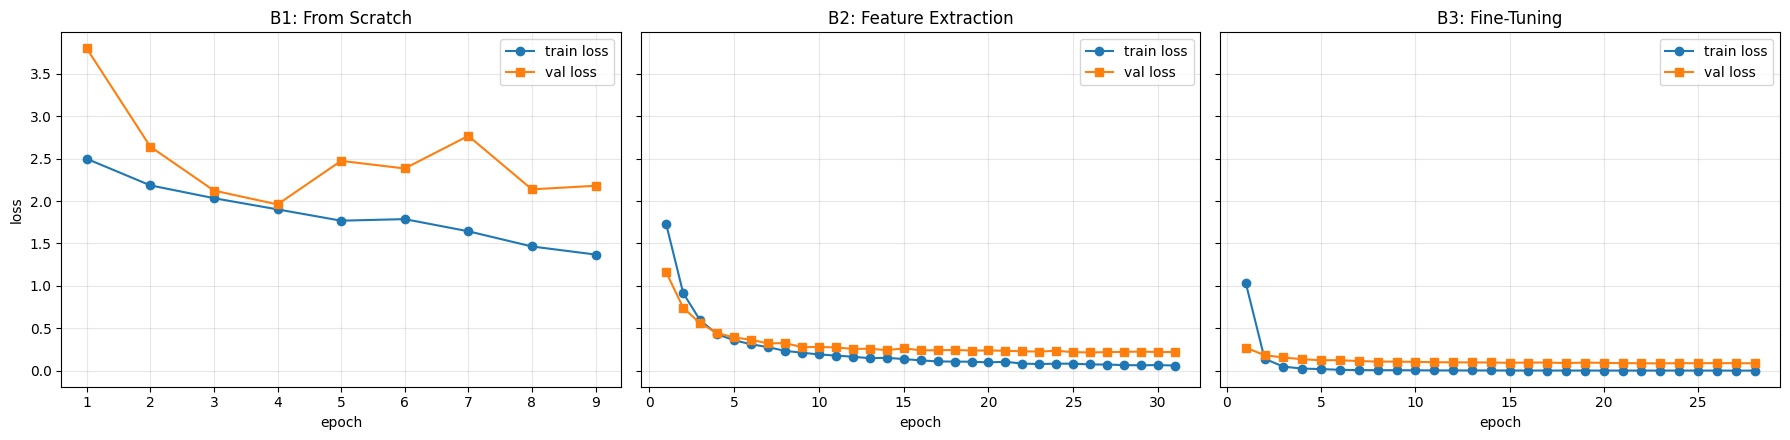

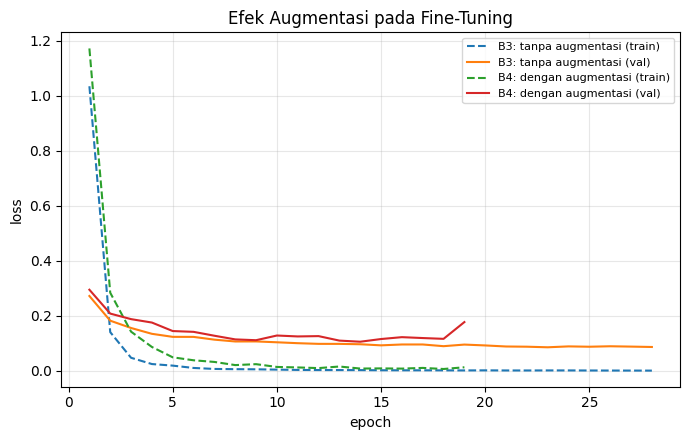

In [15]:
# Kurva training vs validation loss untuk B1, B2, B3 (wajib laporan C1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, hist, title in zip(
    axes,
    [hist_b1, hist_b2, hist_b3],
    ["B1: From Scratch", "B2: Feature Extraction", "B3: Fine-Tuning"],
):
    ep = [h["epoch"] for h in hist]
    ax.plot(ep, [h["train_loss"] for h in hist], marker="o", label="train loss")
    ax.plot(ep, [h["val_loss"] for h in hist], marker="s", label="val loss")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
    ax.grid(alpha=0.3)
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.savefig("logs/curves_B1_B2_B3.png", dpi=120)
plt.show()

# Perbandingan B3 (tanpa aug) vs B4 (dengan aug)
fig, ax = plt.subplots(figsize=(7, 4.5))
for hist, lbl in [(hist_b3, "B3: tanpa augmentasi"), (hist_b4, "B4: dengan augmentasi")]:
    ep = [h["epoch"] for h in hist]
    ax.plot(ep, [h["train_loss"] for h in hist], "--", label=f"{lbl} (train)")
    ax.plot(ep, [h["val_loss"] for h in hist], label=f"{lbl} (val)")
ax.set_title("Efek Augmentasi pada Fine-Tuning")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("logs/curve_B3_vs_B4.png", dpi=120)
plt.show()

## 7. Failure Analysis (C3)

Sampel test yang salah diprediksi model terbaik (dipilih dari val acc terbaik), lengkap sama label asli, prediksi, dan confidence-nya.

Model terbaik: B3_finetune | val acc = 0.9733 | test F1 = 0.96
6 misclassified dari 150 image test


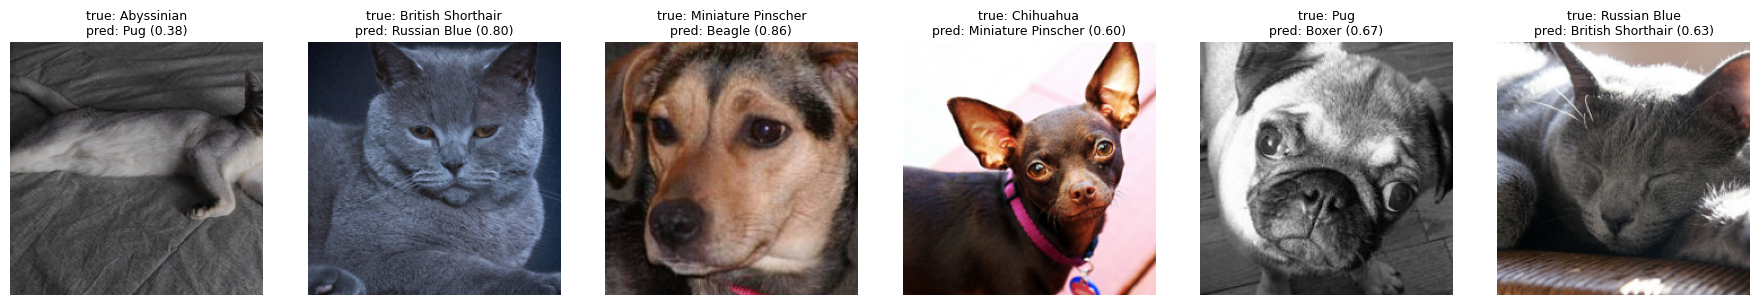

Abyssinian_16.jpg: true=Abyssinian, pred=Pug (0.38)
British_Shorthair_105.jpg: true=British Shorthair, pred=Russian Blue (0.80)
miniature_pinscher_183.jpg: true=Miniature Pinscher, pred=Beagle (0.86)
chihuahua_14.jpg: true=Chihuahua, pred=Miniature Pinscher (0.60)
pug_130.jpg: true=Pug, pred=Boxer (0.67)
Russian_Blue_152.jpg: true=Russian Blue, pred=British Shorthair (0.63)


In [16]:
# Model terbaik dipilih dari validation accuracy — test set hanya untuk evaluasi akhir
best_code = max(RESULTS, key=lambda k: RESULTS[k]["best_val_acc"])
print(f"Model terbaik: {best_code} | val acc = {RESULTS[best_code]['best_val_acc']} | "
      f"test F1 = {RESULTS[best_code]['test_f1_macro']}")

model_best = MODELS[best_code]
model_best.eval()

ds_te = PetSubset(raw_trainval, idx_test, eval_tf, label_map)

wrong, all_true, all_pred = [], [], []
for i in range(len(ds_te)):
    img, true = ds_te[i]
    with torch.no_grad():
        prob = torch.softmax(model_best(img.unsqueeze(0).to(DEVICE)), dim=1)[0]
    pred = int(prob.argmax())
    all_true.append(true)
    all_pred.append(pred)
    if pred != true:
        wrong.append({
            "img": img, "true": true, "pred": pred,
            "conf": float(prob[pred]),
            "file": os.path.basename(str(raw_trainval._images[idx_test[i]])),
        })

print(f"{len(wrong)} misclassified dari {len(idx_test)} image test")

n_show = min(8, len(wrong))
if n_show:
    show_images(
        [w["img"] for w in wrong[:n_show]],
        [f"true: {CLASS_NAMES[w['true']]}\npred: {CLASS_NAMES[w['pred']]} ({w['conf']:.2f})"
         for w in wrong[:n_show]],
        ncols=n_show,
    )
    for w in wrong[:n_show]:
        print(f"{w['file']}: true={CLASS_NAMES[w['true']]}, "
              f"pred={CLASS_NAMES[w['pred']]} ({w['conf']:.2f})")

                    precision    recall  f1-score   support

        Abyssinian       1.00      0.93      0.97        15
 British Shorthair       0.93      0.93      0.93        15
      Russian Blue       0.93      0.93      0.93        15
           Siamese       1.00      1.00      1.00        15
            Sphynx       1.00      1.00      1.00        15
            Beagle       0.94      1.00      0.97        15
             Boxer       0.94      1.00      0.97        15
         Chihuahua       1.00      0.93      0.97        15
Miniature Pinscher       0.93      0.93      0.93        15
               Pug       0.93      0.93      0.93        15

          accuracy                           0.96       150
         macro avg       0.96      0.96      0.96       150
      weighted avg       0.96      0.96      0.96       150



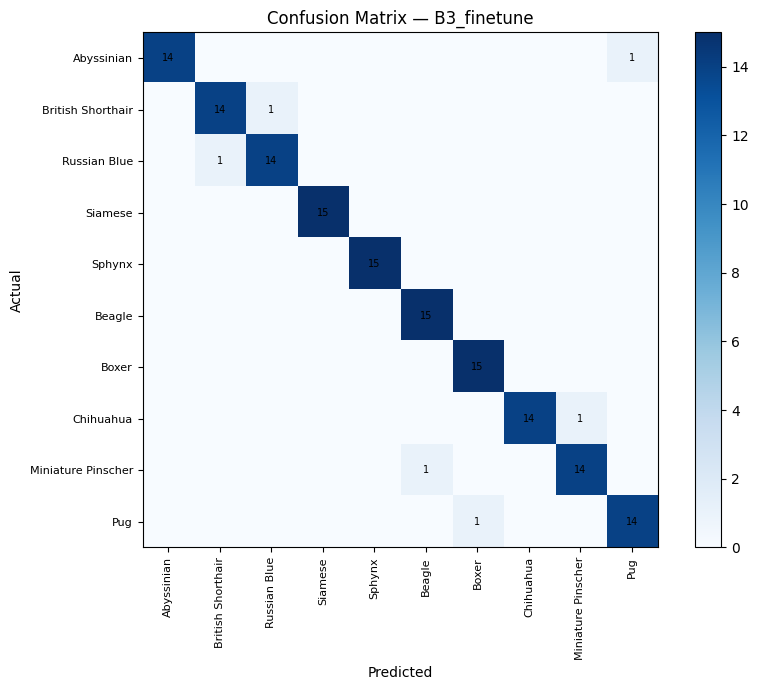

In [17]:
# Classification report + confusion matrix untuk model terbaik
print(classification_report(all_true, all_pred, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(all_true, all_pred)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_KELAS := len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=8)
ax.set_yticks(range(NUM_KELAS))
ax.set_yticklabels(CLASS_NAMES, fontsize=8)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix — {best_code}")
for i in range(NUM_KELAS):
    for j in range(NUM_KELAS):
        if cm[i, j]:
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7)
plt.colorbar(im)
plt.tight_layout()
plt.savefig("logs/confusion_matrix.png", dpi=120)
plt.show()

## 8. (Opsional) Grad-CAM `layer4` — Sebelum vs Sesudah Fine-Tuning (C5)

Bandingin heatmap Grad-CAM di `layer4` antara backbone pretrained murni (B2) sama yang udah di-fine-tune (B4), di image test yang sama.

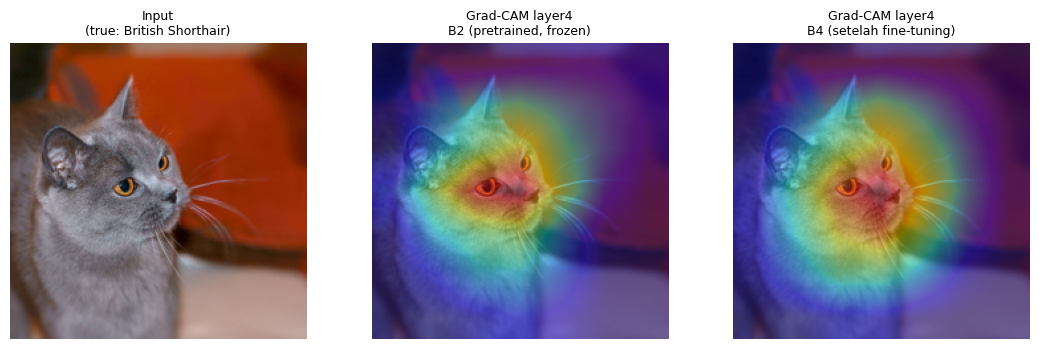

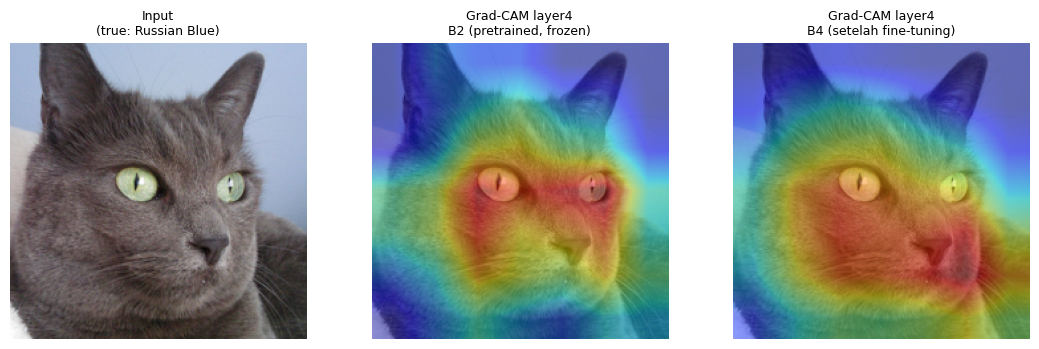

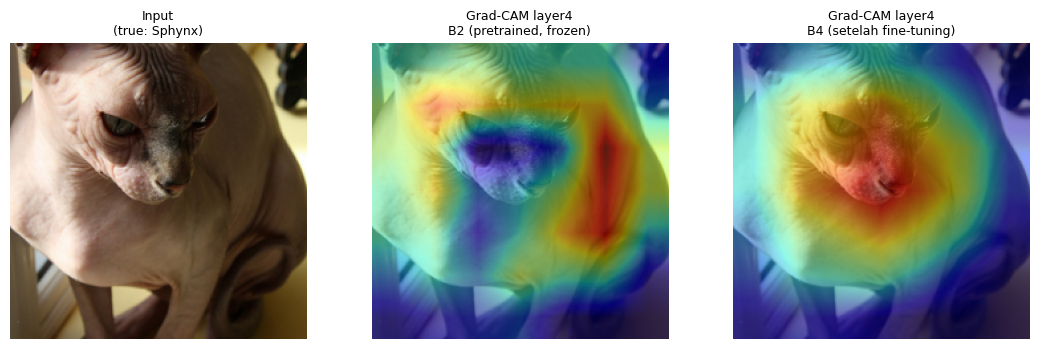

In [18]:
def gradcam(model, target_layer, img_tensor, class_idx):
    model.eval()
    cache = {}
    def fwd_hook(m, i, o):
        cache["feat"] = o.detach()
    def bwd_hook(m, gi, go):
        cache["grad"] = go[0].detach()
    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    x = img_tensor.unsqueeze(0).to(DEVICE).requires_grad_(True)
    out = model(x)
    model.zero_grad()
    out[0, class_idx].backward()
    h1.remove(); h2.remove()

    w = cache["grad"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * cache["feat"]).sum(dim=1, keepdim=True))
    cam = nn.functional.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
    cam = cam[0, 0].cpu().numpy()
    return (cam - cam.min()) / (cam.max() + 1e-8)


# Ambil 3 sampel test pertama
samples = []
with torch.no_grad():
    for i in range(min(12, len(ds_te))):
        x, y = ds_te[i]
        pred = int(model_best(x.unsqueeze(0).to(DEVICE)).argmax(1))
        samples.append({"img": x, "true": y, "pred": pred})
picked = samples[:3]

for s in picked:
    cam_b2 = gradcam(model_b2, model_b2.layer4, s["img"], s["true"])
    cam_b4 = gradcam(model_b4, model_b4.layer4, s["img"], s["true"])

    base = (s["img"] * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
    axes[0].imshow(base); axes[0].set_title(f"Input\n(true: {CLASS_NAMES[s['true']]})", fontsize=9)
    axes[1].imshow(base); axes[1].imshow(cam_b2, cmap="jet", alpha=0.45)
    axes[1].set_title("Grad-CAM layer4\nB2 (pretrained, frozen)", fontsize=9)
    axes[2].imshow(base); axes[2].imshow(cam_b4, cmap="jet", alpha=0.45)
    axes[2].set_title("Grad-CAM layer4\nB4 (setelah fine-tuning)", fontsize=9)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"logs/gradcam_{CLASS_NAMES[s['true']].replace(' ', '_')}.png", dpi=120)
    plt.show()

## 9. Simpan Artefak

Semua raw log (CSV per epoch, summary JSON, bobot terbaik, grafik) dijadiin satu ZIP buat dilampirin.

In [20]:
import shutil
from google.colab import files

shutil.make_archive("experiment_log_", "zip", "logs")
print(os.listdir("logs"))
files.download("experiment_log_.zip")

['summary.json', 'curve_B3_vs_B4.png', 'curves_B1_B2_B3.png', 'B2_feature_extraction_best.pt', 'B5_efficientnet_b0_best.pt', 'log_B3_finetune.csv', 'log_B4_finetune_aug.csv', 'gradcam_Russian_Blue.png', 'log_B1_scratch.csv', 'log_B2_feature_extraction.csv', 'gradcam_Sphynx.png', 'B1_scratch_best.pt', 'B3_finetune_best.pt', 'summary_all.csv', 'B4_finetune_aug_best.pt', 'confusion_matrix.png', 'gradcam_British_Shorthair.png', 'log_B5_efficientnet_b0.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>